# 06 · Evaluation — medical metrics, significance, ablations, Grad-CAM

Everything a reviewer expects, computed on the **held-out test split** with the
tested `src/evaluate.py`:

* per-class precision/recall/F1, macro-F1, **sensitivity & specificity**
* **ROC-AUC** (binary at Stage 1, one-vs-rest for subtypes)
* **calibration** (ECE + reliability diagram)
* confusion matrices
* **McNemar's test**: image-only baseline vs. multimodal on the *same* test set
* **diffusion ablation**: malignant model with vs. without synthetic akiec
* **Grad-CAM** montage (does the model look at the lesion?)
* end-to-end hierarchical pipeline accuracy

Figures are written to `report/figures/` and numbers to `report/results.json`
+ `report/figures/summary.md` for pasting into the report.

---
*Part of: **A Multimodal, Explainable Hierarchical Framework for Skin-Lesion
Classification with Diffusion-Based Augmentation of Rare Malignancies.***
All training/eval logic lives in the tested modules under `src/`; these
notebooks orchestrate them on a Colab T4.

In [ ]:

!pip -q install scikit-learn matplotlib kaggle >/dev/null 2>&1
print("deps ready")

deps ready


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import shutil

DRIVE_PROJECT = '/content/drive/MyDrive/Projects/Skin_Cancer_Research_Grant2024'
#
LOCAL_PROJECT = '/content/Skin_Cancer_Research_Grant2024'

os.makedirs(LOCAL_PROJECT, exist_ok=True)

folders = ['data']

for folder in folders:
    source = os.path.join(DRIVE_PROJECT, folder)
    destination = os.path.join(LOCAL_PROJECT, folder)

    print(f"Copying {folder}...")

    shutil.copytree(
        source,
        destination,
        dirs_exist_ok=True
    )

    print(f"✓ {folder} copied")

print("\nAll folders copied to Colab!")

Copying data...
✓ data copied

All folders copied to Colab!


In [4]:
import os, sys

try:
    PROJECT_DIR = '/content/drive/MyDrive/Projects/Skin_Cancer_Research_Grant2024'
except Exception:
    PROJECT_DIR = os.path.abspath('..')

SRC       = os.path.join(PROJECT_DIR, 'src')
MODELS_DIR= os.path.join(PROJECT_DIR, 'models')
DATA_DIR  = '/content/Skin_Cancer_Research_Grant2024/data'
FIG_DIR   = os.path.join(PROJECT_DIR, 'report', 'figures')
SPLIT_CSV = os.path.join(MODELS_DIR, 'ham_split.csv')
PREP_JSON = os.path.join(MODELS_DIR, 'preprocessing.json')
for d in (MODELS_DIR, DATA_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

assert os.path.isdir(SRC), f"src/ not found at {SRC} — set PROJECT_DIR correctly"
sys.path.insert(0, SRC)
print("PROJECT_DIR =", PROJECT_DIR)

PROJECT_DIR = /content/drive/MyDrive/Projects/Skin_Cancer_Research_Grant2024


In [5]:
import os, json
import numpy as np, pandas as pd
from tensorflow.keras.models import load_model
import data as D, metadata as M, evaluate as ev

proc = M.MetadataProcessor.load(PREP_JSON)
df = pd.read_csv(SPLIT_CSV)
results = {}

def predict_probs(model, ds):
    return model.predict(ds, verbose=0)

def eval_stage(stage, pretty):
    # Evaluate baseline + multimodal for one stage on its TEST slice.
    classes = D.STAGE_CLASSES[stage]
    sdf = D.filter_for_stage(df, stage)
    te = sdf[sdf.split == 'test']
    y_true = te['label_idx'].to_numpy()

    base = load_model(os.path.join(MODELS_DIR, f'{stage}_baseline.keras'))
    mm   = load_model(os.path.join(MODELS_DIR, f'{stage}_multimodal.keras'))

    ds_b = D.make_dataset(te, stage, None, multimodal=False, batch_size=64, training=False)
    ds_m = D.make_dataset(te, stage, proc, multimodal=True, batch_size=64, training=False)
    pb = predict_probs(base, ds_b)
    pm = predict_probs(mm, ds_m)

    m_base = ev.summarize_predictions(y_true, pb, classes)
    m_mm   = ev.summarize_predictions(y_true, pm, classes)
    m_mm['ece'] = ev.expected_calibration_error(y_true, pm)
    mcnemar = ev.mcnemar_test(y_true, pb.argmax(1), pm.argmax(1))

    # Figures (multimodal is the headline model).
    ev.plot_confusion_matrix(y_true, pm.argmax(1), classes,
                             os.path.join(FIG_DIR, f'{stage}_confusion.png'),
                             title=f'{pretty} — confusion (multimodal)')
    ev.plot_roc_curves(y_true, pm, classes, os.path.join(FIG_DIR, f'{stage}_roc.png'))
    ev.plot_reliability(y_true, pm, os.path.join(FIG_DIR, f'{stage}_reliability.png'))

    print(f"\n=== {pretty} ===")
    print(f"  baseline   acc={m_base['accuracy']:.3f}  macroF1={m_base['macro_f1']:.3f}")
    print(f"  multimodal acc={m_mm['accuracy']:.3f}  macroF1={m_mm['macro_f1']:.3f}")
    if 'sensitivity' in m_mm:
        print(f"  multimodal sensitivity={m_mm['sensitivity']:.3f}  specificity={m_mm['specificity']:.3f}")
    print(f"  McNemar p (exact)={mcnemar.get('p_value_exact')}")
    return {'baseline': m_base, 'multimodal': m_mm, 'mcnemar': mcnemar}

In [6]:
results['stage1']    = eval_stage('stage1',    'Stage 1 · benign vs malignant')
results['benign']    = eval_stage('benign',    'Stage 2a · benign subtype')
results['malignant'] = eval_stage('malignant', 'Stage 2b · malignant subtype')


=== Stage 1 · benign vs malignant ===
  baseline   acc=0.802  macroF1=0.681
  multimodal acc=0.827  macroF1=0.720
  multimodal sensitivity=0.536  specificity=0.898
  McNemar p (exact)=0.009769982885939301

=== Stage 2a · benign subtype ===
  baseline   acc=0.783  macroF1=0.623
  multimodal acc=0.793  macroF1=0.605
  McNemar p (exact)=0.44571222099285324



=== Stage 2b · malignant subtype ===
  baseline   acc=0.676  macroF1=0.567
  multimodal acc=0.642  macroF1=0.506
  McNemar p (exact)=0.2749903961710005


## Diffusion ablation — malignant model **with vs. without** synthetic akiec

In [7]:
classes = D.STAGE_CLASSES['malignant']
mal = D.filter_for_stage(df, 'malignant')
te = mal[mal.split == 'test']
y_true = te['label_idx'].to_numpy()
ds_m = D.make_dataset(te, 'malignant', proc, multimodal=True, batch_size=64, training=False)

akiec_i = classes.index('akiec')
def akiec_recall(probs):
    m = ev.summarize_predictions(y_true, probs, classes)
    return m['per_class']['akiec']['recall'], m['macro_f1']

mm_plain = load_model(os.path.join(MODELS_DIR, 'malignant_multimodal.keras'))
r_plain, f_plain = akiec_recall(predict_probs(mm_plain, ds_m))

ablation = {'no_synth': {'akiec_recall': r_plain, 'macro_f1': f_plain}}
aug_path = os.path.join(MODELS_DIR, 'malignant_multimodal_aug.keras')
if os.path.exists(aug_path):
    mm_aug = load_model(aug_path)
    r_aug, f_aug = akiec_recall(predict_probs(mm_aug, ds_m))
    ablation['with_synth'] = {'akiec_recall': r_aug, 'macro_f1': f_aug}
    print(f"akiec recall : {r_plain:.3f} -> {r_aug:.3f}  (Δ {r_aug-r_plain:+.3f})")
    print(f"macro-F1     : {f_plain:.3f} -> {f_aug:.3f}  (Δ {f_aug-f_plain:+.3f})")
else:
    print("Run notebook 05 first to produce malignant_multimodal_aug.keras")
results['diffusion_ablation'] = ablation

akiec recall : 0.184 -> 0.265  (Δ +0.082)
macro-F1     : 0.506 -> 0.637  (Δ +0.131)


## End-to-end hierarchical pipeline (on the global test split)

In [8]:
from PIL import Image
from pipeline import SkinLesionPipeline, MALIGNANT_CLASSES

pipe = SkinLesionPipeline.from_dir(MODELS_DIR)
test = df[df.split == 'test']
SUBTYPES = ['nv','bkl','vasc','mel','bcc','akiec']   # 'df' can't be sub-classified

def _clean(v):
    return None if (pd.isna(v) or str(v) == 'unknown') else v

n_stage1_correct = 0; n = 0
n_sub_correct = 0; n_sub = 0
mal_tp = 0; mal_fn = 0
for _, row in test.iterrows():
    try:
        img = Image.open(row['image_path']).convert('RGB')
    except Exception:
        continue
    res = pipe.predict(img, age=_clean(row.get('age')),
                       sex=_clean(row.get('sex')),
                       localization=_clean(row.get('localization')),
                       gradcam=False)
    n += 1
    true_mal = row['dx'] in MALIGNANT_CLASSES
    n_stage1_correct += int(res.is_malignant == true_mal)
    if true_mal:
        mal_tp += int(res.is_malignant); mal_fn += int(not res.is_malignant)
    if row['dx'] in SUBTYPES:
        n_sub += 1
        n_sub_correct += int(res.subtype_label == row['dx'])

e2e = {
    'stage1_accuracy': n_stage1_correct / max(n, 1),
    'malignant_sensitivity': mal_tp / max(mal_tp + mal_fn, 1),
    'end_to_end_subtype_accuracy': n_sub_correct / max(n_sub, 1),
    'n_test': int(n),
}
print(json.dumps(e2e, indent=2))
results['end_to_end'] = e2e

{
  "stage1_accuracy": 0.83166999334664,
  "malignant_sensitivity": 0.6006825938566553,
  "end_to_end_subtype_accuracy": 0.6816958277254375,
  "n_test": 1503
}


## Grad-CAM montage (Stage-1 multimodal)

In [14]:
CLASS_NAMES = {
    "nv": "Melanocytic nevi",
    "mel": "Melanoma",
    "bkl": "Benign keratosis-like lesions",
    "bcc": "Basal cell carcinoma",
    "akiec": "Actinic keratoses / intraepithelial carcinoma",
    "vasc": "Vascular lesions",
    "df": "Dermatofibroma"
}

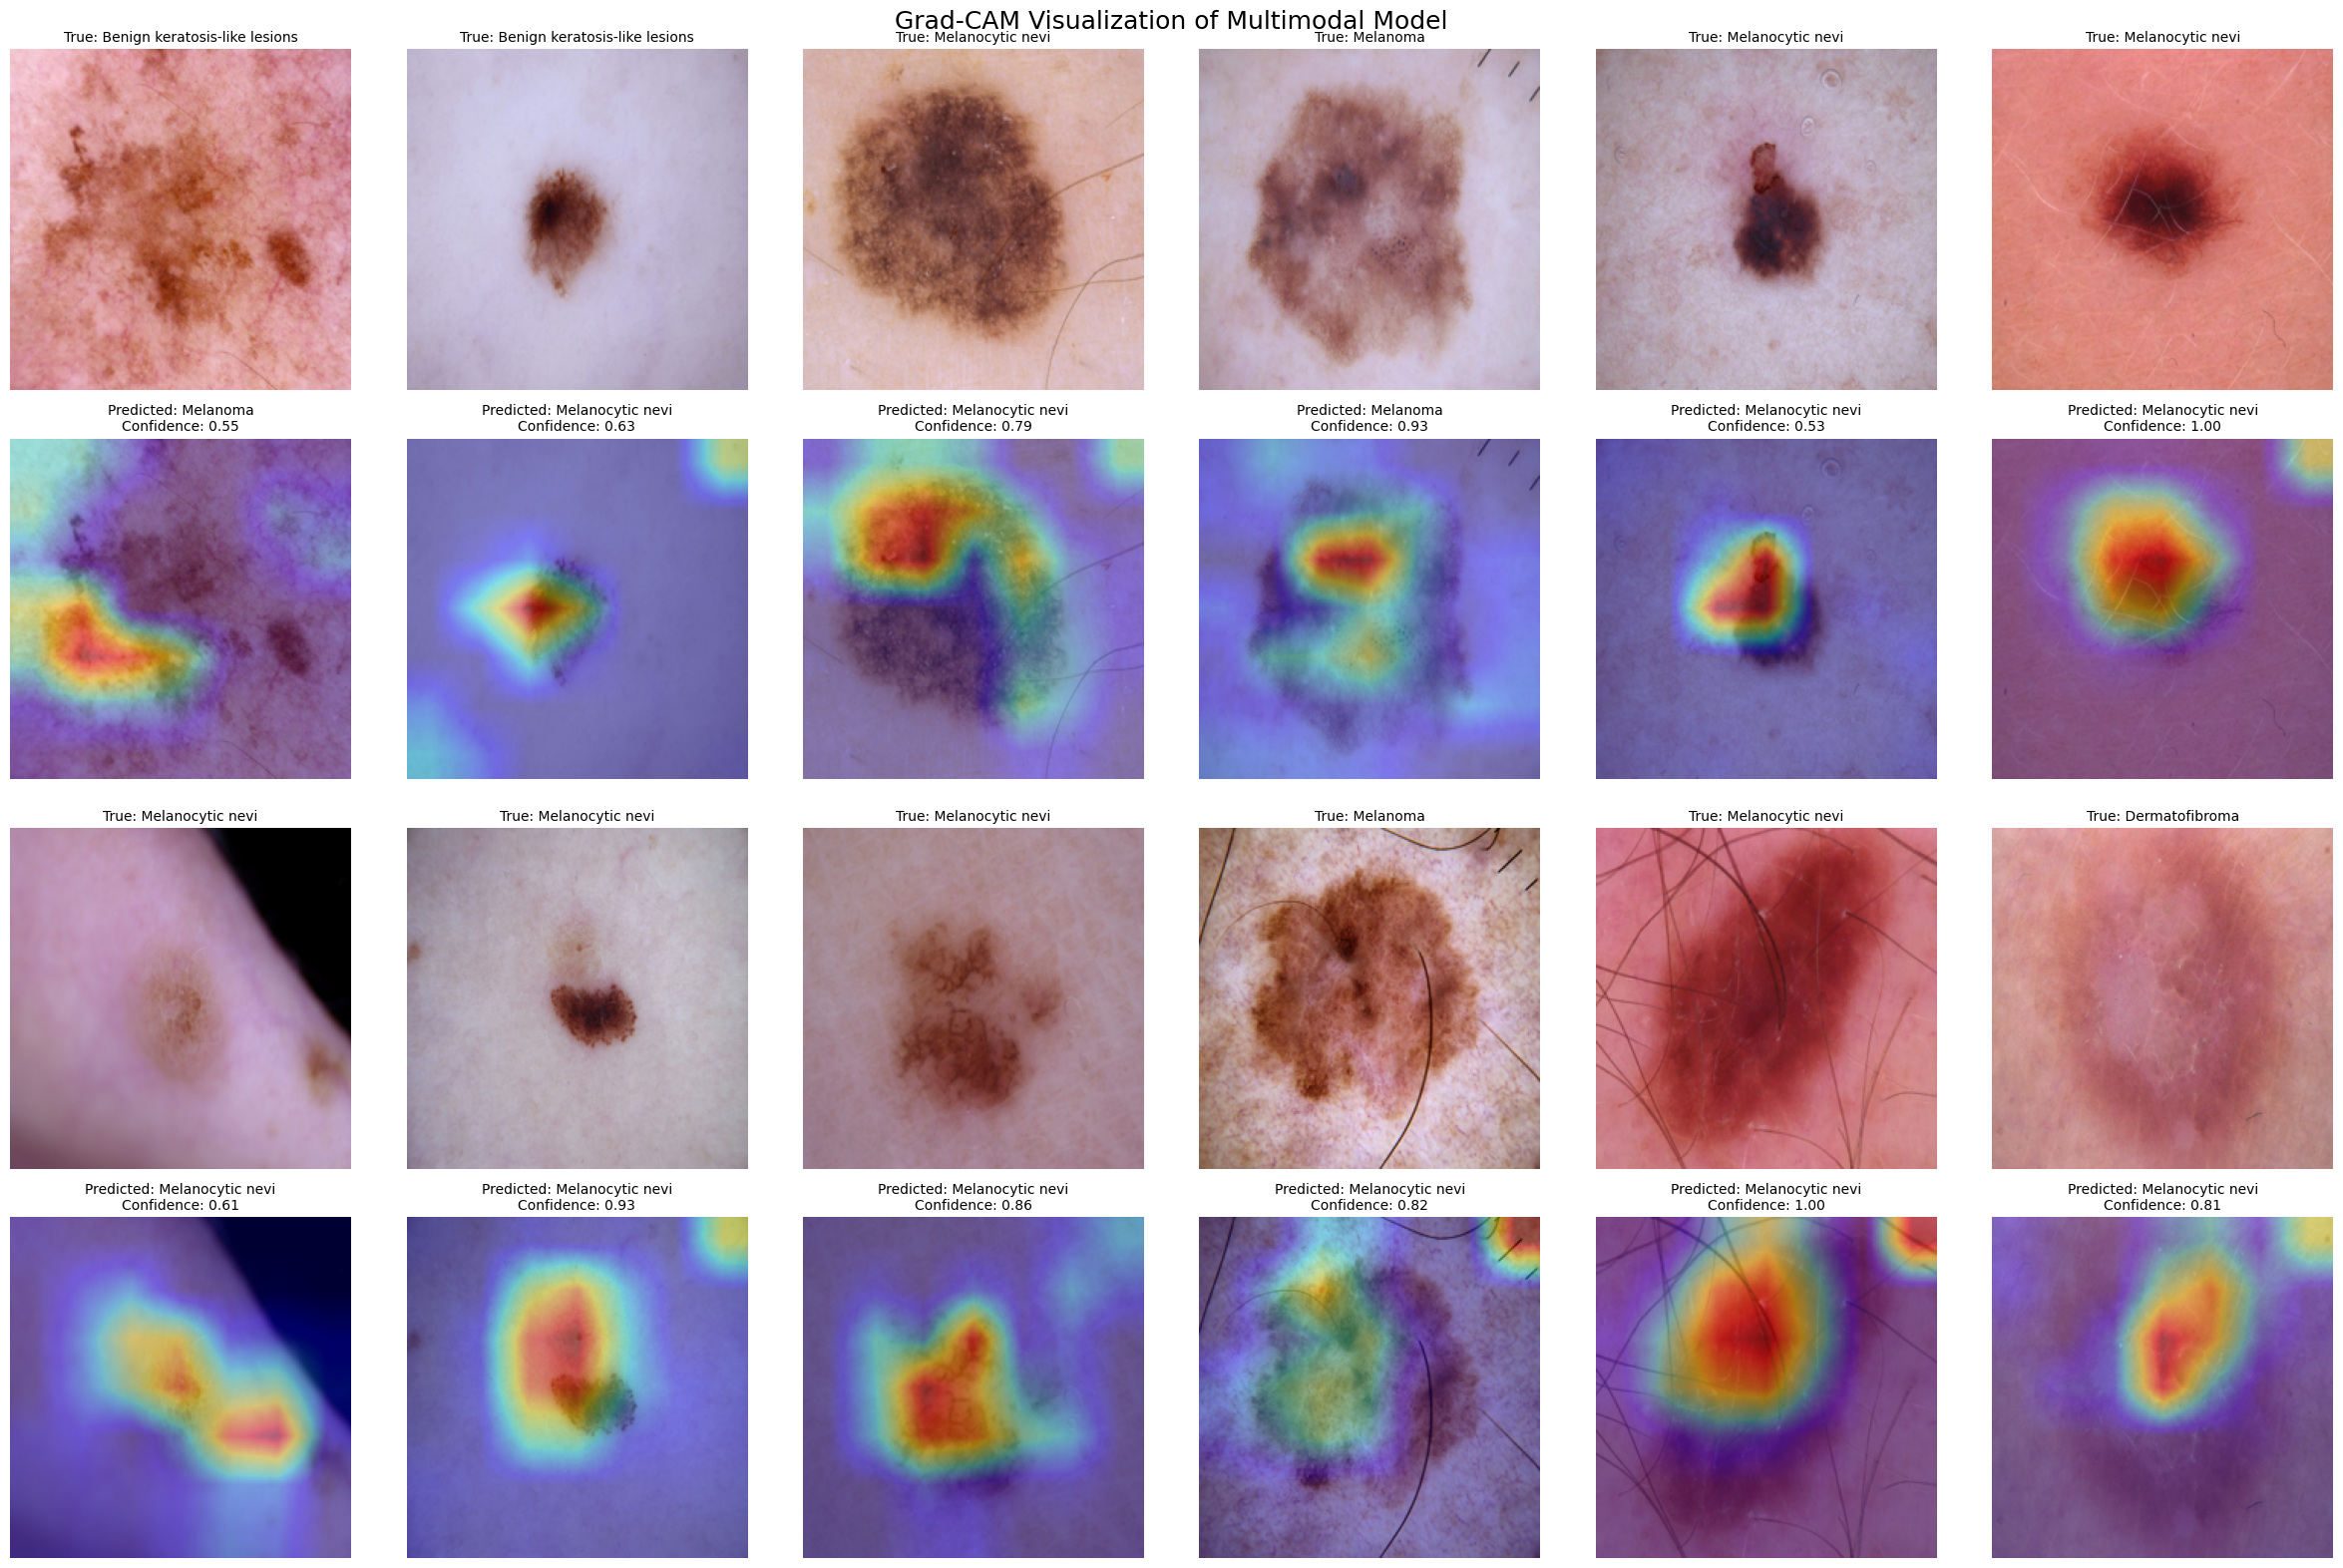

Saved: /content/drive/MyDrive/Projects/Skin_Cancer_Research_Grant2024/report/figures/gradcam_montage.png


In [19]:
%matplotlib inline

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.models import load_model
from gradcam import make_gradcam_heatmap, overlay_heatmap

stage1 = load_model(os.path.join(MODELS_DIR, "stage1_multimodal.keras"))
test_df = df[df["split"] == "test"]
sample = test_df.sample(min(12, len(test_df)), random_state=1)

fig, axes = plt.subplots(4, 6, figsize=(24, 16))
MODEL_CLASSES = ["nv", "mel", "bkl", "bcc", "akiec", "vasc", "df"]

for j, (_, row) in enumerate(sample.iterrows()):
    img = np.asarray(Image.open(row["image_path"]).convert("RGB").resize((224, 224)), dtype="float32")
    meta = proc.transform_one(age=row.get("age"), sex=str(row.get("sex")), localization=str(row.get("localization"))).astype("float32")
    true_code = str(row["dx"])
    true_name = CLASS_NAMES.get(true_code, true_code)

    try:
        hm, idx, conf = make_gradcam_heatmap(stage1, img, meta=meta)
        ov = overlay_heatmap(img, hm)
        pred_code = MODEL_CLASSES[idx]
        pred_name = CLASS_NAMES.get(pred_code, pred_code)
    except Exception as e:
        print(f"Grad-CAM failed for {row['image_path']}:", repr(e))
        ov = img.astype("uint8")
        pred_name = "Unknown"
        conf = float("nan")

    if j < 6:
        r = 0
        grad_r = 1
        c = j
    else:
        r = 2
        grad_r = 3
        c = j - 6

    axes[r, c].imshow(img.astype("uint8"))
    axes[r, c].set_title(f"True: {true_name}", fontsize=10)
    axes[r, c].axis("off")

    axes[grad_r, c].imshow(ov)
    axes[grad_r, c].set_title(f"Predicted: {pred_name}\nConfidence: {conf:.2f}", fontsize=10)
    axes[grad_r, c].axis("off")

fig.suptitle("Grad-CAM Visualization of Multimodal Model", fontsize=18)
plt.tight_layout()

output_path = os.path.join(FIG_DIR, "gradcam_montage.png")
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", output_path)

## Persist results (JSON + a markdown snippet for the report)

In [10]:
ev.save_metrics_json(results, os.path.join(PROJECT_DIR, 'report', 'results.json'))

def _fmt(x): return '—' if x is None else f'{x:.3f}'
lines = ['# Auto-generated results summary', '']
lines.append('## Baseline vs. multimodal (test set)')
lines.append('| Stage | Model | Acc | Macro-F1 | Sensitivity | Spec | ROC-AUC | McNemar p |')
lines.append('|---|---|---|---|---|---|---|---|')
for stage, pretty in [('stage1','Stage 1'),('benign','Stage 2a'),('malignant','Stage 2b')]:
    R = results[stage]; p = R['mcnemar'].get('p_value_exact')
    for mdl in ['baseline','multimodal']:
        m = R[mdl]
        auc = m.get('roc_auc', m.get('roc_auc_ovr_macro'))
        lines.append(f"| {pretty} | {mdl} | {_fmt(m['accuracy'])} | {_fmt(m['macro_f1'])} | "
                     f"{_fmt(m.get('sensitivity'))} | {_fmt(m.get('specificity'))} | {_fmt(auc)} | "
                     f"{'' if mdl=='baseline' else _fmt(p)} |")
lines += ['', '## Diffusion ablation (malignant subtype)']
ab = results['diffusion_ablation']
lines.append('| Variant | akiec recall | macro-F1 |')
lines.append('|---|---|---|')
for k in ['no_synth','with_synth']:
    if k in ab: lines.append(f"| {k} | {_fmt(ab[k]['akiec_recall'])} | {_fmt(ab[k]['macro_f1'])} |")
lines += ['', '## End-to-end pipeline', '']
for k, v in results['end_to_end'].items():
    lines.append(f"- **{k}**: {v:.3f}" if isinstance(v, float) else f"- **{k}**: {v}")

open(os.path.join(FIG_DIR, 'summary.md'), 'w').write('\n'.join(lines))
print('\n'.join(lines))

# Auto-generated results summary

## Baseline vs. multimodal (test set)
| Stage | Model | Acc | Macro-F1 | Sensitivity | Spec | ROC-AUC | McNemar p |
|---|---|---|---|---|---|---|---|
| Stage 1 | baseline | 0.802 | 0.681 | 0.478 | 0.880 | 0.818 |  |
| Stage 1 | multimodal | 0.827 | 0.720 | 0.536 | 0.898 | 0.852 | 0.010 |
| Stage 2a | baseline | 0.783 | 0.623 | — | — | 0.914 |  |
| Stage 2a | multimodal | 0.793 | 0.605 | — | — | 0.907 | 0.446 |
| Stage 2b | baseline | 0.676 | 0.567 | — | — | 0.828 |  |
| Stage 2b | multimodal | 0.642 | 0.506 | — | — | 0.771 | 0.275 |

## Diffusion ablation (malignant subtype)
| Variant | akiec recall | macro-F1 |
|---|---|---|
| no_synth | 0.184 | 0.506 |
| with_synth | 0.265 | 0.637 |

## End-to-end pipeline

- **stage1_accuracy**: 0.832
- **malignant_sensitivity**: 0.601
- **end_to_end_subtype_accuracy**: 0.682
- **n_test**: 1503
